# Sequence Models for Arabic NLP
## Lab Report: Relevance Scoring & Language Modeling

In this lab, we build, train, and evaluate four recurrent neural network architectures—**RNN, Bidirectional RNN (BiRNN), GRU, and LSTM**—using PyTorch. We apply these sequence models to a custom-scraped Arabic text dataset.

### Project Workflow
1. **Scraping:** We collected Arabic text samples about Artificial Intelligence (*الذكاء الاصطناعي*) and unrelated subjects using `requests` and `BeautifulSoup` to create a balanced dataset.
2. **Preprocessing:** We implemented a tailored NLP pipeline for Arabic morphology, covering normalization, tokenization, stop-word removal, and lemmatization via `qalsadi`.
3. **Labeling:** We calculated a weak-supervision relevance score (0–10) using lexicon density and TF-IDF similarity to construct our targets.
4. **Modeling:** We trained the four models as classifiers/regressors on sequence data.
5. **Language Modeling:** We extended our analysis by testing the models on a next-word prediction task, evaluating them with perplexity and BLEU scores.

In [ ]:

!pip install -q beautifulsoup4 lxml nltk qalsadi tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, re, time, random, math, json, warnings, collections
from functools import lru_cache
from urllib.parse import urljoin, urlparse, unquote, quote
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
from bs4 import BeautifulSoup
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader, TensorDataset

# ------------------------------ global configuration ------------------------------
FAST_DEBUG        = False   # True -> tiny run (few trials / epochs) just to check that everything executes
REFRESH_SCRAPING  = False   # True -> scrape again even if data/raw_texts.csv already exists
SEED              = 42

DATA_DIR, MODEL_DIR = "data", "models"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(MODEL_DIR, exist_ok=True)
RAW_CSV     = f"{DATA_DIR}/raw_texts.csv"       # scraped chunks (+ source / url)
DATASET_CSV = f"{DATA_DIR}/dataset.csv"         # the lab dataset: Text, Score
FULL_CSV    = f"{DATA_DIR}/dataset_full.csv"    # same + metadata used by the notebook

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__)

device: cuda | torch 2.14.1+cu130


## 1 · Data collection (web scraping)

**Topic:** *الذكاء الاصطناعي* (Artificial Intelligence).

Sources (all Arabic):
* **Arabic Wikipedia** – core AI articles, *neighbouring* articles (computers, programming, statistics…) and *unrelated* articles (sport, literature…).
* **News sites** – the AI sections of Sky News Arabia, Euronews Arabic, i24NEWS Arabic, Al Jazeera, plus a few non-AI sections (sport, culture) of the same sites.

Why include unrelated pages? The score is a **relevance** score between 0 and 10, so the dataset must contain texts that are very relevant, partly relevant and not relevant at all — otherwise a model has nothing to learn.

Each page is cut into **chunks of ≈ 50–150 words** (one chunk = one sample). This gives hundreds of samples from a few dozen pages and keeps the sequences at a size RNNs can handle.

In [ ]:
# ------------------------------ low-level scraping utilities ------------------------------
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; MBD-DeepLearning-Lab/1.0; student project)",
           "Accept-Language": "ar,en;q=0.7"}
SESSION = requests.Session(); SESSION.headers.update(HEADERS)

def fetch(url, retries=2, timeout=20, delay=0.6):
    # returns the raw bytes of an HTML page, or None (never raises)
    for attempt in range(retries + 1):
        try:
            r = SESSION.get(url, timeout=timeout)
            if r.status_code == 200 and "html" in r.headers.get("Content-Type", ""):
                time.sleep(delay)                  # be polite with the servers
                return r.content
            if r.status_code in (403, 404, 410):   # no point in retrying
                break
        except requests.RequestException:
            pass
        time.sleep(1.5 * (attempt + 1))
    return None

def arabic_ratio(s):
    letters = [c for c in s if c.isalpha()]
    return sum("؀" <= c <= "ۿ" for c in letters) / len(letters) if letters else 0.0

JUNK_TAGS = ["script", "style", "noscript", "nav", "footer", "header", "aside", "form",
             "figure", "figcaption", "table", "sup", "button", "iframe", "svg"]

def extract_paragraphs(html, min_chars=50):
    # keeps the Arabic <p> paragraphs of the main content of a page
    soup = BeautifulSoup(html, "lxml")
    for t in soup(JUNK_TAGS): t.decompose()
    for t in soup.select(".reference, .mw-editsection, .navbox, .infobox, .hatnote, .thumb"): t.decompose()
    root = soup.select_one("#mw-content-text") or soup.find("article") or soup.find("main") or soup.body
    if root is None: return []
    paras = []
    for p in root.find_all("p"):
        txt = re.sub(r"\s+", " ", p.get_text(" ", strip=True))
        txt = re.sub(r"\[[^\]]{0,40}\]", "", txt).strip()          # [1], [citation needed] ...
        if len(txt) >= min_chars and arabic_ratio(txt) >= 0.7:
            paras.append(txt)
    return paras

def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[\.\!\?؟])\s+", text) if s.strip()]

def make_chunks(paragraphs, min_words=50, max_words=150):
    # groups consecutive paragraphs/sentences into chunks of roughly min_words..max_words words
    units = []
    for p in paragraphs:
        units.extend(split_sentences(p) if len(p.split()) > max_words else [p])
    chunks, cur, n = [], [], 0
    for u in units:
        w = len(u.split())
        if cur and n + w > max_words and n >= min_words:
            chunks.append(" ".join(cur)); cur, n = [], 0
        cur.append(u); n += w
    if cur and n >= min_words: chunks.append(" ".join(cur))
    return chunks

BAD_PARTS = ("/tag/", "/tags/", "/author", "/video", "/program", "/live", "/photo", "/gallery",
             "/topic", "/search", "/category", "/page/", "/about", "/contact", "/privacy")

def find_article_links(listing_url, html, domains):
    # picks the links of a listing page that look like articles and belong to the allowed domains
    soup = BeautifulSoup(html, "lxml")
    links = []
    for a in soup.find_all("a", href=True):
        u = urljoin(listing_url, a["href"]).split("#")[0].split("?")[0]
        p = urlparse(u)
        if p.scheme not in ("http", "https"): continue
        if not any(p.netloc == d or p.netloc.endswith("." + d) for d in domains): continue
        path = unquote(p.path)
        if any(b in path.lower() for b in BAD_PARTS): continue
        segs = [s for s in path.split("/") if s]
        dated      = re.search(r"/20\d{2}/\d{1,2}/\d{1,2}/", path)       # /2025/05/14/slug
        numeric_id = re.search(r"/\d{5,}(-|/|$)", path)                  # /technology/1905513-slug
        long_slug  = len(segs) >= 2 and len(segs[-1]) > 25
        if dated or numeric_id or long_slug:
            links.append(u)
    return list(dict.fromkeys(links))            # de-duplicate, keep order

def scrape_page(url, kind, source, max_chunks):
    html = fetch(url)
    if html is None: return None
    chunks = make_chunks(extract_paragraphs(html))[:max_chunks]
    return [dict(source=source, kind=kind, url=url, text=c) for c in chunks]

In [ ]:
# ------------------------------ what to scrape (edit freely) ------------------------------
def wiki_url(title): return "https://ar.wikipedia.org/wiki/" + quote(title.replace(" ", "_"))

WIKI_CORE = ["الذكاء الاصطناعي", "تعلم الآلة", "التعلم العميق", "شبكة عصبية اصطناعية", "معالجة اللغات الطبيعية",
             "الرؤية الحاسوبية", "التعلم المعزز", "الذكاء الاصطناعي التوليدي", "شات جي بي تي", "نموذج لغوي كبير",
             "تاريخ الذكاء الاصطناعي", "أخلاقيات الذكاء الاصطناعي", "اختبار تورنغ", "الذكاء الاصطناعي العام",
             "التعلم الخاضع للإشراف", "التعلم غير الخاضع للإشراف", "تعدين البيانات", "نظام خبير",
             "شبكة عصبية تلافيفية", "شبكة عصبية متكررة", "علم البيانات", "الروبوتات"]
WIKI_NEAR = ["حاسوب", "إنترنت", "خوارزمية", "لغة برمجة", "علم الحاسوب", "إحصاء", "أتمتة", "هاتف ذكي",
             "أمن المعلومات", "حوسبة سحابية", "رياضيات", "فيزياء", "هندسة كهربائية", "إلكترونيات", "بيانات"]
WIKI_OFF  = ["كرة القدم", "المطبخ العربي", "الأدب العربي", "الشعر العربي", "التاريخ الإسلامي",
             "الحرب العالمية الثانية", "نهر النيل", "الصحراء الكبرى", "زراعة", "الطقس", "سياحة",
             "موسيقى", "سينما", "فلسفة", "تاريخ مصر القديمة", "المحيط الأطلسي"]

NEWS_SOURCES = [
    # kind = "news-ai"  -> AI sections / tags     |   kind = "news-off" -> unrelated sections (low-relevance examples)
    dict(name="skynewsarabia", kind="news-ai", domains=["skynewsarabia.com", "snabusiness.com"],
         listings=["https://www.skynewsarabia.com/artificial_intelligence"]),
    dict(name="euronews_ar", kind="news-ai", domains=["arabic.euronews.com"],
         listings=[f"https://arabic.euronews.com/tag/artificial-intelligence?p={i}" for i in range(1, 9)]),
    dict(name="i24news_ar", kind="news-ai", domains=["i24news.tv"],
         listings=["https://www.i24news.tv/ar/tags/ذكاء-اصطناعي"]),
    dict(name="aljazeera_tech", kind="news-ai", domains=["aljazeera.net"],
         listings=["https://www.aljazeera.net/tech/"]),
    dict(name="aljazeera_sport", kind="news-off", domains=["aljazeera.net"],
         listings=["https://www.aljazeera.net/sport/"]),
    dict(name="skynewsarabia_sport", kind="news-off", domains=["skynewsarabia.com"],
         listings=["https://www.skynewsarabia.com/sport"]),
    dict(name="aljazeera_culture", kind="news-off", domains=["aljazeera.net"],
         listings=["https://www.aljazeera.net/culture/"]),
]
MAX_CHUNKS_PER_PAGE, MAX_ARTICLES_PER_SOURCE = 30, 40

def collect():
    rows, failed = [], []
    for kind, titles in [("wiki-core", WIKI_CORE), ("wiki-near", WIKI_NEAR), ("wiki-off", WIKI_OFF)]:
        for t in tqdm(titles, desc=kind):
            out = scrape_page(wiki_url(t), kind, "ar.wikipedia.org", MAX_CHUNKS_PER_PAGE)
            if out: rows += out
            else:   failed.append(("wikipedia", t))
    for src in NEWS_SOURCES:
        links = []
        for lst in src["listings"]:
            html = fetch(lst)
            if html is None: failed.append((src["name"], lst)); continue
            links += find_article_links(lst, html, src["domains"])
        links = list(dict.fromkeys(links))[:MAX_ARTICLES_PER_SOURCE]
        for u in tqdm(links, desc=src["name"]):
            out = scrape_page(u, src["kind"], src["name"], MAX_CHUNKS_PER_PAGE)
            if out: rows += out
            else:   failed.append((src["name"], u))
    return pd.DataFrame(rows), failed

if os.path.exists(RAW_CSV) and not REFRESH_SCRAPING:
    raw_df = pd.read_csv(RAW_CSV, encoding="utf-8-sig")
    print(f"loaded cached {RAW_CSV}")
else:
    raw_df, failed = collect()
    raw_df = raw_df.drop_duplicates("text").reset_index(drop=True)
    raw_df.to_csv(RAW_CSV, index=False, encoding="utf-8-sig")
    print(f"{len(failed)} pages failed (first 10): {failed[:10]}")

print(f"\n{len(raw_df)} text chunks from {raw_df['url'].nunique()} pages")
display(raw_df.groupby(["kind", "source"]).agg(pages=("url", "nunique"), chunks=("text", "size")))
if len(raw_df) < 500:
    print("⚠️ fewer than 500 chunks: add more pages in the lists above and re-run with REFRESH_SCRAPING = True")

wiki-core:   0%|          | 0/22 [00:00<?, ?it/s]

wiki-near:   0%|          | 0/15 [00:00<?, ?it/s]

wiki-off:   0%|          | 0/16 [00:00<?, ?it/s]

skynewsarabia:   0%|          | 0/40 [00:00<?, ?it/s]

euronews_ar: 0it [00:00, ?it/s]

i24news_ar: 0it [00:00, ?it/s]

... (2 outputs left out)

skynewsarabia_sport:   0%|          | 0/36 [00:00<?, ?it/s]

aljazeera_culture:   0%|          | 0/23 [00:00<?, ?it/s]

28 pages failed (first 10): [('wikipedia', 'شبكة عصبية اصطناعية'), ('wikipedia', 'التعلم الخاضع للإشراف'), ('wikipedia', 'التعلم غير الخاضع للإشراف'), ('wikipedia', 'تعدين البيانات'), ('wikipedia', 'شبكة عصبية تلافيفية'), ('skynewsarabia', 'https://www.skynewsarabia.com/podcast/hayatouna/1905580-تعنيف-الطفل-قبل-والديه-يقسو-الأمان'), ('skynewsarabia', 'https://www.skynewsarabia.com/podcast/atheer_alkora/1905174-كأس-أمم-إفريقيا-2027-الرقم-القياسي-العربي-خطر'), ('skynewsarabia', 'https://www.skynewsarabia.com/podcast/psycological_health/1904599-هرمون-السعادة-نملك-مفتاح-التحكم-فيه'), ('skynewsarabia', 'https://www.skynewsarabia.com/podcast/flashback/1904595-جمهورية-إنجلترا'), ('euronews_ar', 'https://arabic.euronews.com/tag/artificial-intelligence?p=1')]

1743 text chunks from 211 pages


pages  chunks
kind      source                            
news-ai   aljazeera_tech          39     274
          skynewsarabia           36     166
news-off  aljazeera_culture       22     184
          aljazeera_sport         38     121
          skynewsarabia_sport     28      64
wiki-core ar.wikipedia.org        17     293
wiki-near ar.wikipedia.org        15     275
wiki-off  ar.wikipedia.org        16     366

## 2 · Arabic NLP preprocessing pipeline

Arabic is morphologically rich (one written word can contain a conjunction, a preposition, the article *ال*, a stem and a pronoun), so we clean carefully.

| Step | Implementation | Why |
|---|---|---|
| **Normalisation** | remove URLs, `[1]`-style references, diacritics (*tashkeel*), *tatweel* (ـ), digits & punctuation; lower-case Latin; unify `أ إ آ → ا`, `ى → ي`, `ة → ه` (**after** stemming / lemmatisation, which need the original spelling) | the same word is written in many ways |
| **Tokenisation** | regex on Arabic / Latin letters | words are space separated once punctuation is removed |
| **Stop-word removal** | NLTK Arabic list + our own list (normalised the same way) | frequent function words carry no topic information |
| **Stemming** | NLTK `ISRIStemmer` (root/light stemmer) | collapses derived forms, shrinks the vocabulary |
| **Lemmatisation** | `qalsadi` Arabic lemmatiser (falls back to the stemmer if unavailable) | gives real dictionary forms (*الأطفال → طفل*) |
| **Discretisation** | scores → *low / medium / high* (section 4) | lets us use classification metrics |

The classification models read the **lemmatised, stop-word-free** tokens (`TOKEN_MODE`). The language-model section (7) reads the **normalised-only** tokens so that generated text stays readable.

In [ ]:
ARABIC_DIACRITICS = re.compile(r"[ؗ-ًؚ-ْٰۖ-ۭ]")
TOKEN_RE = re.compile(r"[ء-يa-z]+")
IS_ARABIC_TOKEN = re.compile(r"^[ء-ي]+$")

def light_clean(text):
    # cleaning that keeps the ORIGINAL spelling (the stemmer / lemmatiser work better on it)
    text = str(text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)           # URLs
    text = re.sub(r"\[[^\]]*\]", " ", text)                       # [1], [citation needed]
    text = ARABIC_DIACRITICS.sub("", text)                        # tashkeel
    text = text.replace("ـ", "")                             # tatweel
    text = text.lower()
    text = re.sub(r"[^ء-يa-z\s]", " ", text)            # keep only Arabic + Latin letters
    return re.sub(r"\s+", " ", text).strip()

def unify_letters(text):
    text = re.sub("[إأآٱ]", "ا", text)                            # alef variants
    return text.replace("ى", "ي").replace("ة", "ه")               # alef maqsura, ta marbuta

def normalize_ar(text):                                           # full normalisation = clean + unify letters
    return unify_letters(light_clean(text))

def tokenize(text):
    return TOKEN_RE.findall(text)

# ---------------- stop-words ----------------
CUSTOM_STOPWORDS = """
في من على إلى الى عن مع هذا هذه ذلك تلك هؤلاء أولئك هنا هناك هنالك هو هي هم هن هما أنا نحن أنت أنتم
التي الذي الذين اللذان اللتان اللواتي كان كانت كانوا يكون تكون يكونون ليس ليست أن إن أنه أنها إنه إنها أنهم
لكن ولكن أو أم ثم بل قد لقد لا لم لن ما ماذا لماذا كيف أين متى كل بعض غير سوى بين حتى عند عندما بعد قبل
فوق تحت خلال حول دون ضد منذ إذا إذ أي أيضا أيضاً فقط جدا جداً كما كذلك حيث حين مثل نحو لدى لدي
عليه عليها عليهم إليه إليها منه منها منهم فيه فيها فيهم به بها بهم له لها لهم لك لي بأن بأنه بأنها
وقد وهو وهي وهم وفي ومن وعلى وإلى وعن ومع وأن وإن ولا وما قال قالت يقول وقال تم يتم أصبح أصبحت يعد ضمن
أحد إحدى ذات ذو ذي عبر عدة اما أما إما لو لولا هل كلما كلا كلتا هذان هاتان
"""
def load_stopwords():
    words = set(CUSTOM_STOPWORDS.split())
    try:
        import nltk
        try: nltk.data.find("corpora/stopwords")
        except LookupError: nltk.download("stopwords", quiet=True)
        from nltk.corpus import stopwords
        words |= set(stopwords.words("arabic"))
        src = "NLTK + custom list"
    except Exception as e:
        src = f"custom list only (NLTK stop-words unavailable: {type(e).__name__})"
    sw = {normalize_ar(w) for w in words}
    sw.discard("")
    return sw, src

STOPWORDS, sw_src = load_stopwords()
print(f"{len(STOPWORDS)} stop-words ({sw_src})")

# ---------------- stemming (ISRI) and lemmatisation (qalsadi) ----------------
from nltk.stem.isri import ISRIStemmer
_isri = ISRIStemmer()

@lru_cache(maxsize=None)
def stem(word):
    if not IS_ARABIC_TOKEN.match(word): return word
    s = _isri.stem(word)
    return s if len(s) > 1 else word

try:
    from qalsadi.lemmatizer import Lemmatizer
    _lemmatizer = Lemmatizer()
    LEMMA_OK = True
except Exception as e:
    print("qalsadi lemmatiser not available -> falling back to stemming:", type(e).__name__)
    LEMMA_OK = False

@lru_cache(maxsize=None)
def lemma(word):
    if not LEMMA_OK or not IS_ARABIC_TOKEN.match(word): return stem(word)
    try:
        parts = str(_lemmatizer.lemmatize(word)).split()
        return parts[0] if parts and len(parts[0]) > 1 else word
    except Exception:
        return word

TOKEN_MODE = "lemma" if LEMMA_OK else "stem"        # "lemma" | "stem" | "clean"  (clean = stop-words removed only)

def preprocess(text, mode=TOKEN_MODE, remove_stopwords=True):
    toks = tokenize(light_clean(text))                 # original spelling is kept for the stemmer / lemmatiser
    if remove_stopwords:
        toks = [t for t in toks if unify_letters(t) not in STOPWORDS]
    toks = [t for t in toks if len(t) > 1]
    if mode == "stem":    toks = [stem(t) for t in toks]
    elif mode == "lemma": toks = [lemma(t) for t in toks]
    return [t for t in (unify_letters(t) for t in toks) if len(t) > 1]     # unify letters at the very end

# ---------------- demo ----------------
demo = "تعتمدُ تقنياتُ الذكاءِ الاصطناعيِّ الحديثةُ على الشبكاتِ العصبيّةِ العميقةِ لتحليلِ البياناتِ الضخمةِ وتدريبِ النماذجِ."
toks = tokenize(light_clean(demo)); nostop = [t for t in toks if unify_letters(t) not in STOPWORDS]
print("original      :", demo)
print("normalised    :", normalize_ar(demo))
print("tokens        :", toks)
print("no stop-words :", nostop)
print("stems (ISRI)  :", [stem(t) for t in nostop])
print("lemmas        :", [lemma(t) for t in nostop])
print("final tokens  :", preprocess(demo))

667 stop-words (NLTK + custom list)
original      : تعتمدُ تقنياتُ الذكاءِ الاصطناعيِّ الحديثةُ على الشبكاتِ العصبيّةِ العميقةِ لتحليلِ البياناتِ الضخمةِ وتدريبِ النماذجِ.
normalised    : تعتمد تقنيات الذكاء الاصطناعي الحديثه علي الشبكات العصبيه العميقه لتحليل البيانات الضخمه وتدريب النماذج
tokens        : ['تعتمد', 'تقنيات', 'الذكاء', 'الاصطناعي', 'الحديثة', 'على', 'الشبكات', 'العصبية', 'العميقة', 'لتحليل', 'البيانات', 'الضخمة', 'وتدريب', 'النماذج']
no stop-words : ['تعتمد', 'تقنيات', 'الذكاء', 'الاصطناعي', 'الحديثة', 'الشبكات', 'العصبية', 'العميقة', 'لتحليل', 'البيانات', 'الضخمة', 'وتدريب', 'النماذج']
stems (ISRI)  : ['عمد', 'تقن', 'ذكء', 'صطناع', 'حدث', 'شبك', 'عصب', 'عمق', 'حلل', 'بين', 'ضخم', 'درب', 'اذج']
lemmas        : ['اعتمد', 'تقني', 'ذكاء', 'اصطناع', 'حديث', 'شبكة', 'عصب', 'عميق', 'تحليل', 'بيان', 'ضخم', 'تدريب', 'أنموذج']
final tokens  : ['اعتمد', 'تقني', 'ذكاء', 'اصطناع', 'حديث', 'شبكه', 'عصب', 'عميق', 'تحليل', 'بيان', 'ضخم', 'تدريب', 'انموذج']


## 3 · Building the labelled dataset (`Text`, `Score` ∈ [0, 10])
 we build the score **automatically and transparently** (weak supervision) from two signals that are computed on the *raw* text:

1. **Lexicon density** – weighted number of topic terms (*الذكاء الاصطناعي, تعلم الآلة, الشبكات العصبية, خوارزمية, تدريب, بيانات…*) per 100 tokens. Multi-word terms are matched first.
2. **TF-IDF cosine similarity** to a *topic profile* (the mean TF-IDF vector of the core AI Wikipedia chunks).

`score = 10 · (0.6 · density_scaled + 0.4 · cosine_scaled)`, where both signals are min-max scaled between their 2nd and 98th percentile, then rounded to 0.5.

The neural models never see the lexicon or the TF-IDF vectors: they only see the preprocessed token sequences, so they must **learn the notion of "relevance" from word sequences**.

lexicon density:   0%|          | 0/1743 [00:00<?, ?it/s]

saved data/dataset.csv and data/dataset_full.csv


,Text,Score
1085,داخل أديرة في الدنمارك ترقد هياكل عظمية قادت العلماء إلى اكتشاف علمي غريب، يتعلق بدقة ...,1.5
1117,"أحيطت لعبة ""جي تي إيه-6"" -منذ الإعلان الأول عنها في ديسمبر/كانون الأول 2023- بهالة فري...",1.5
593,في القوانين هناك قاعدتان تتعلقان بلعب الكرة، وهي: الكرة داخل اللعب و الكرة خارج اللعب ...,0.5
842,وفي الوقت ذاته كان « أديسون » ينقل السنما إلى مرحلتها الحاسمة وذلك باختراعه الفيلم الح...,1.0
861,تبدأ الفلسفة الإيرانية قبل الإسلام بعمل زرادشت ، أحد أوائل المروجين للتوحيد وللثنائي ب...,0.5
799,السياحة هي السفر بهدف الترفيه أو التطبيب أو الاكتشاف، وتشمل السياحة توفير الخدمات المت...,0.5
351,لإضفاء التحسينات الممكنة حتى في بعض الخوارزميات «المبنية بشكل جيد»، وهذا ابتكار هام يت...,2.5
1576,لم تعد الطبيعة في الرواية العربية مجرد شجرة تشهد على لقاء العشاق، أو نهر يعبره الأبطال...,0.5



mean score per kind of page:


,count,mean,std,min,max
kind,,,,,
news-ai,440,2.10,1.69,0.0,8.0
news-off,369,0.54,0.43,0.0,3.5
wiki-core,293,5.65,2.56,1.0,10.0
wiki-near,275,2.17,1.31,0.5,9.0
wiki-off,366,0.80,0.51,0.0,4.0


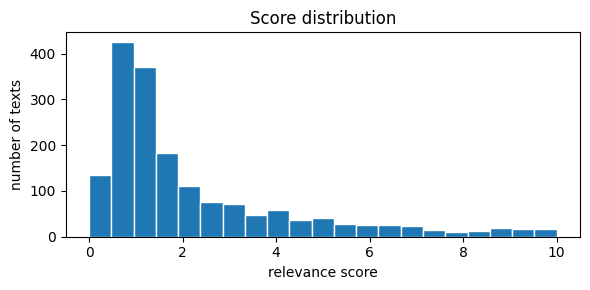

In [ ]:
LEXICON = {   # term -> weight
    "الذكاء الاصطناعي": 3.0, "الذكاء الصناعي": 3.0, "تعلم الآلة": 3.0, "التعلم الآلي": 3.0, "التعلم العميق": 3.0,
    "الشبكات العصبية": 3.0, "الشبكة العصبية": 3.0, "معالجة اللغات الطبيعية": 3.0, "معالجة اللغة الطبيعية": 3.0,
    "الرؤية الحاسوبية": 2.5, "نموذج لغوي": 2.5, "النماذج اللغوية": 2.5, "شات جي بي تي": 2.5, "chatgpt": 2.5,
    "gpt": 2.0, "openai": 2.0, "أوبن إيه آي": 2.0, "نموذج": 1.0, "نماذج": 1.0, "خوارزمية": 1.5, "خوارزميات": 1.5,
    "روبوت": 1.5, "روبوتات": 1.5, "تدريب": 1.5, "بيانات": 1.0, "حاسوب": 1.0, "برمجة": 1.0, "تعلم": 0.8,
    "تقنية": 0.7, "تقنيات": 0.7, "تكنولوجيا": 0.7, "رقمي": 0.5, "حوسبة": 1.0, "معالج": 0.7, "ذكي": 0.7, "ذكية": 0.7,
}
def strip_al(tok):                      # drop the definite article for matching only
    return tok[2:] if tok.startswith("ال") and len(tok) > 4 else tok

LEX = {tuple(strip_al(t) for t in tokenize(normalize_ar(k))): w for k, w in LEXICON.items()}
MAX_NGRAM = max(len(k) for k in LEX)

def lexicon_density(text):
    toks = [strip_al(t) for t in tokenize(normalize_ar(text))]
    n, i, hit = max(len(toks), 1), 0, 0.0
    while i < len(toks):
        for k in range(MAX_NGRAM, 0, -1):                 # longest match first
            key = tuple(toks[i:i + k])
            if len(key) == k and key in LEX:
                hit += LEX[key]; i += k; break
        else:
            i += 1
    return 100.0 * hit / n

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def pct_scale(x, lo=2, hi=98):
    a, b = np.percentile(x, [lo, hi])
    return np.clip((x - a) / (b - a + 1e-9), 0, 1)

full = raw_df.copy()
full["density"] = [lexicon_density(t) for t in tqdm(full["text"], desc="lexicon density")]

norm_texts = full["text"].map(normalize_ar)
tfidf = TfidfVectorizer(token_pattern=r"[ء-يa-z]{2,}", ngram_range=(1, 2), min_df=2,
                        sublinear_tf=True, max_features=60000)
X_tfidf = tfidf.fit_transform(norm_texts)

profile_mask = (full["kind"] == "wiki-core").values
if profile_mask.sum() < 20:                      # Wikipedia scraping failed -> use the densest chunks instead
    profile_mask = full["density"].values >= np.quantile(full["density"], 0.8)
profile = np.asarray(X_tfidf[profile_mask].mean(axis=0))
full["cosine"] = cosine_similarity(X_tfidf, profile).ravel()

raw_score = 0.6 * pct_scale(full["density"].values) + 0.4 * pct_scale(full["cosine"].values)
full["score"] = np.round(10 * raw_score * 2) / 2                      # 0 … 10 by steps of 0.5

full[["text", "score"]].rename(columns={"text": "Text", "score": "Score"}).to_csv(DATASET_CSV, index=False, encoding="utf-8-sig")
full.to_csv(FULL_CSV, index=False, encoding="utf-8-sig")
print(f"saved {DATASET_CSV} and {FULL_CSV}")

pd.set_option("display.max_colwidth", 90)
display(full[["text", "score"]].rename(columns={"text": "Text", "score": "Score"}).sample(8, random_state=SEED))
print("\nmean score per kind of page:")
display(full.groupby("kind")["score"].agg(["count", "mean", "std", "min", "max"]).round(2))

plt.figure(figsize=(6, 3)); plt.hist(full["score"], bins=21, edgecolor="white")
plt.xlabel("relevance score"); plt.ylabel("number of texts"); plt.title("Score distribution"); plt.tight_layout(); plt.show()

## 4 · Applying the pipeline, discretisation, split, vocabulary, tensors

* **Two token views** per text: `tok_cls` (stop-words removed + lemmas → classification) and `tok_lm` (normalised only → language models).
* **Discretisation:** the continuous score is cut into 3 balanced classes (*low / medium / high*) at the tertiles. Classification metrics are computed on the discretised scores, while the networks are trained as **regressors** on the continuous score (a sigmoid output scaled to 0–10).
* **Split 70 / 15 / 15** with `StratifiedGroupKFold`: stratified on the class **and grouped by page**, so chunks of the same article never end up in both train and test (otherwise we would measure memorisation of articles, not generalisation).
* **Vocabulary** is built on the *training set only* (words seen < 2 times → `<unk>`).

In [ ]:
df = full.reset_index(drop=True).copy()
df["tok_cls"] = [preprocess(t, TOKEN_MODE) for t in tqdm(df["text"], desc=f"preprocess ({TOKEN_MODE})")]
df["tok_lm"]  = [tokenize(normalize_ar(t)) for t in df["text"]]
df = df[df["tok_cls"].map(len) >= 5].reset_index(drop=True)
print(f"{len(df)} samples | mean #tokens: cls = {df['tok_cls'].map(len).mean():.1f}, lm = {df['tok_lm'].map(len).mean():.1f}")

# ---------------- discretisation of the score ----------------
CLASS_NAMES = ["low", "medium", "high"]
q = np.quantile(df["score"], [1 / 3, 2 / 3])
THRESHOLDS = [float(q[0]), float(q[1])]
def discretize(scores):                      # class 0: s <= t0 | class 1: t0 < s <= t1 | class 2: s > t1
    return np.digitize(np.asarray(scores), THRESHOLDS, right=True)
df["label"] = discretize(df["score"])
print("thresholds:", THRESHOLDS, "| class counts:", dict(zip(CLASS_NAMES, np.bincount(df["label"], minlength=3))))

# ---------------- stratified + grouped split ----------------
from sklearn.model_selection import StratifiedGroupKFold
groups = df["url"].fillna("none").values if "url" in df else np.arange(len(df))
sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [idx for _, idx in sgkf.split(df, df["label"], groups=groups)]
test_idx, val_idx, train_idx = folds[0], folds[1], np.concatenate(folds[2:])
print(f"train/val/test = {len(train_idx)}/{len(val_idx)}/{len(test_idx)}")
for name, idx in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"  {name:5s} class share:", np.round(np.bincount(df.loc[idx, "label"], minlength=3) / len(idx), 2))

# ---------------- vocabulary (train only) and tensors ----------------
PAD, UNK = "<pad>", "<unk>"
def build_vocab(token_lists, min_freq=2, max_size=20000):
    cnt = collections.Counter(t for toks in token_lists for t in toks)
    itos = [PAD, UNK] + [w for w, c in cnt.most_common(max_size) if c >= min_freq]
    return itos, {w: i for i, w in enumerate(itos)}

itos, stoi = build_vocab(df.loc[train_idx, "tok_cls"])
lens = df["tok_cls"].map(len)
MAX_LEN = int(min(200, np.percentile(lens, 95)))
print(f"vocabulary: {len(itos)} words | MAX_LEN = {MAX_LEN} (95th percentile of the lengths)")
print("most frequent tokens:", itos[2:22])

def to_tensors(idx):
    toklists, scores = df.loc[idx, "tok_cls"].tolist(), df.loc[idx, "score"].values
    X = torch.zeros(len(toklists), MAX_LEN, dtype=torch.long)
    L = torch.ones(len(toklists), dtype=torch.long)
    for i, toks in enumerate(toklists):
        ids = [stoi.get(t, 1) for t in toks[:MAX_LEN]]
        if ids: X[i, :len(ids)] = torch.tensor(ids); L[i] = len(ids)
    y = torch.tensor(scores / 10.0, dtype=torch.float32)          # targets scaled to [0, 1]
    return X, L, y

train_set, val_set, test_set = to_tensors(train_idx), to_tensors(val_idx), to_tensors(test_idx)
unk_rate = (val_set[0] == 1).sum().item() / max(val_set[1].sum().item(), 1)
print(f"share of <unk> tokens in the validation set: {unk_rate:.1%}")

preprocess (lemma):   0%|          | 0/1743 [00:00<?, ?it/s]

1743 samples | mean #tokens: cls = 87.6, lm = 118.4
thresholds: [1.0, 2.0] | class counts: {'low': np.int64(929), 'medium': np.int64(294), 'high': np.int64(520)}
train/val/test = 1394/156/193
  train class share: [0.52 0.17 0.31]
  val   class share: [0.51 0.15 0.34]
  test  class share: [0.62 0.2  0.19]
vocabulary: 6340 words | MAX_LEN = 112 (95th percentile of the lengths)
most frequent tokens: ['عام', 'شركه', 'ذكاء', 'عالم', 'اصطناع', 'بيان', 'عمل', 'يم', 'اله', 'شكل', 'نظام', 'حاسوب', 'استخدام', 'علم', 'رئيس', 'كبير', 'حال', 'عمله', 'مجال', 'الرياض']
share of <unk> tokens in the validation set: 7.7%


## 5 · Models and hyper-parameter tuning

One configurable network covers the four architectures:

```
tokens → Embedding → [RNN | BiRNN | GRU | LSTM] → pooling → MLP head → sigmoid × 10
```

| Name | `rnn_type` | `bidirectional` |
|---|---|---|
| RNN | `nn.RNN` (tanh) | no |
| BiRNN | `nn.RNN` (tanh) | yes |
| GRU | `nn.GRU` | no |
| LSTM | `nn.LSTM` | no |

*Padding is handled with `pack_padded_sequence`, so the recurrent layers never read padding.* **Pooling** is a tuned hyper-parameter: `last` (final hidden state – the textbook choice, harder for a vanilla RNN on long sequences) or `mean` (masked mean over all time steps).

**Loss:** MSE · **Optimiser:** AdamW + `ReduceLROnPlateau` + gradient clipping · **Early stopping** on the validation loss.

**Tuning:** the *same* list of random configurations (plus a baseline) is evaluated for every architecture on the validation set  a fair comparison. The best configuration of each architecture is then retrained for longer and evaluated once on the test set.

In [ ]:
class RelevanceNet(nn.Module):
    def __init__(self, vocab_size, rnn_type="LSTM", bidirectional=False, emb_dim=128, hidden=128,
                 layers=1, dropout=0.3, pooling="mean"):
        super().__init__()
        self.pooling = pooling
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        rnn_cls = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden, num_layers=layers, batch_first=True, bidirectional=bidirectional,
                           dropout=dropout if layers > 1 else 0.0)
        out_dim = hidden * (2 if bidirectional else 1)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Sequential(nn.Linear(out_dim, out_dim // 2), nn.ReLU(), nn.Dropout(dropout),
                                  nn.Linear(out_dim // 2, 1))

    def forward(self, x, lengths):
        packed = pack_padded_sequence(self.drop(self.emb(x)), lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, hn = self.rnn(packed)
        if self.pooling == "last":
            hn = hn[0] if isinstance(hn, tuple) else hn                  # LSTM returns (h, c)
            feat = torch.cat([hn[-2], hn[-1]], dim=1) if self.rnn.bidirectional else hn[-1]
        else:                                                              # masked mean over time
            out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
            mask = (torch.arange(x.size(1), device=x.device)[None, :] < lengths.to(x.device)[:, None]).unsqueeze(-1).float()
            feat = (out * mask).sum(1) / mask.sum(1).clamp(min=1)
        return torch.sigmoid(self.head(self.drop(feat))).squeeze(-1)      # relevance in [0, 1]  (x10 = score)

ARCHS = {"RNN":   dict(rnn_type="RNN",  bidirectional=False),
         "BiRNN": dict(rnn_type="RNN",  bidirectional=True),
         "GRU":   dict(rnn_type="GRU",  bidirectional=False),
         "LSTM":  dict(rnn_type="LSTM", bidirectional=False)}

def make_loader(split, batch_size, shuffle):
    X, L, y = split
    return DataLoader(TensorDataset(X, L, y), batch_size=batch_size, shuffle=shuffle)

def run_epoch(model, loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for x, l, y in loader:
            pred = model(x.to(DEVICE), l)
            loss = F.mse_loss(pred, y.to(DEVICE))
            if train:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total += loss.item() * len(y); n += len(y)
    return total / n

def fit(arch, cfg, epochs, patience=6, verbose=False):
    set_seed()
    model = RelevanceNet(len(itos), **ARCHS[arch],
                         **{k: cfg[k] for k in ("emb_dim", "hidden", "layers", "dropout", "pooling")}).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    tr, va = make_loader(train_set, cfg["batch_size"], True), make_loader(val_set, 128, False)
    best, hist, bad = dict(val=float("inf"), state=None, epoch=0), dict(train=[], val=[]), 0
    for ep in range(1, epochs + 1):
        tl, vl = run_epoch(model, tr, opt), run_epoch(model, va)
        sched.step(vl); hist["train"].append(tl); hist["val"].append(vl)
        if vl < best["val"] - 1e-6:
            best.update(val=vl, epoch=ep, state={k: v.detach().cpu().clone() for k, v in model.state_dict().items()}); bad = 0
        else:
            bad += 1
            if bad >= patience: break
        if verbose and (ep == 1 or ep % 5 == 0):
            print(f"  [{arch}] epoch {ep:3d} | train MSE {tl:.4f} | val MSE {vl:.4f} | val RMSE {math.sqrt(vl) * 10:.2f}")
    model.load_state_dict(best["state"])
    return model, best, hist

# ---------------- search space ----------------
N_TRIALS     = 2 if FAST_DEBUG else 8      # configurations tried per architecture
TUNE_EPOCHS  = 2 if FAST_DEBUG else 12
FINAL_EPOCHS = 3 if FAST_DEBUG else 40

SEARCH_SPACE = {"emb_dim": [64, 128, 200], "hidden": [64, 128, 256], "layers": [1, 2],
                "dropout": [0.2, 0.3, 0.5], "lr": [5e-4, 1e-3, 3e-3], "batch_size": [16, 32, 64],
                "pooling": ["last", "mean"], "weight_decay": [0.0, 1e-4, 1e-3]}
BASELINE = dict(emb_dim=128, hidden=128, layers=1, dropout=0.3, lr=1e-3, batch_size=32, pooling="mean", weight_decay=1e-4)
rng = random.Random(SEED)
trial_cfgs = [BASELINE] + [{k: rng.choice(v) for k, v in SEARCH_SPACE.items()} for _ in range(N_TRIALS - 1)]

rows = []
for arch in ARCHS:
    for t, cfg in enumerate(tqdm(trial_cfgs, desc=f"tuning {arch}")):
        t0 = time.time()
        _, best, _ = fit(arch, cfg, TUNE_EPOCHS)
        rows.append(dict(arch=arch, trial=t, val_RMSE=math.sqrt(best["val"]) * 10, best_epoch=best["epoch"],
                         secs=round(time.time() - t0, 1), **cfg))
tuning_df = pd.DataFrame(rows)
tuning_df.to_csv(f"{DATA_DIR}/tuning_results.csv", index=False)
best_cfg = {a: trial_cfgs[int(g.sort_values("val_RMSE").iloc[0]["trial"])] for a, g in tuning_df.groupby("arch")}

print("\nbest validation RMSE (score points) per architecture / pooling:")
display(tuning_df.pivot_table(index="arch", columns="pooling", values="val_RMSE", aggfunc="min").round(3))
print("best configuration per architecture:")
for a, c in best_cfg.items(): print(f"  {a:6s}", c)

tuning RNN:   0%|          | 0/8 [00:00<?, ?it/s]

tuning BiRNN:   0%|          | 0/8 [00:00<?, ?it/s]

tuning GRU:   0%|          | 0/8 [00:00<?, ?it/s]

tuning LSTM:   0%|          | 0/8 [00:00<?, ?it/s]


best validation RMSE (score points) per architecture / pooling:


pooling,last,mean
arch,,
BiRNN,1.896,1.082
GRU,0.907,0.791
LSTM,1.070,0.728
RNN,2.156,1.142


best configuration per architecture:
  BiRNN  {'emb_dim': 128, 'hidden': 64, 'layers': 1, 'dropout': 0.3, 'lr': 0.0005, 'batch_size': 16, 'pooling': 'mean', 'weight_decay': 0.0}
  GRU    {'emb_dim': 128, 'hidden': 128, 'layers': 1, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 32, 'pooling': 'mean', 'weight_decay': 0.0001}
  LSTM   {'emb_dim': 128, 'hidden': 128, 'layers': 1, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 32, 'pooling': 'mean', 'weight_decay': 0.0001}
  RNN    {'emb_dim': 128, 'hidden': 128, 'layers': 1, 'dropout': 0.3, 'lr': 0.001, 'batch_size': 32, 'pooling': 'mean', 'weight_decay': 0.0001}



=== RNN ===
  [RNN] epoch   1 | train MSE 0.0555 | val MSE 0.0638 | val RMSE 2.53
  [RNN] epoch   5 | train MSE 0.0090 | val MSE 0.0234 | val RMSE 1.53
  [RNN] epoch  10 | train MSE 0.0054 | val MSE 0.0146 | val RMSE 1.21
  [RNN] epoch  15 | train MSE 0.0038 | val MSE 0.0124 | val RMSE 1.11
  [RNN] epoch  20 | train MSE 0.0035 | val MSE 0.0139 | val RMSE 1.18
  best epoch: 17 | val RMSE 1.095

=== BiRNN ===
  [BiRNN] epoch   1 | train MSE 0.0625 | val MSE 0.0822 | val RMSE 2.87
  [BiRNN] epoch   5 | train MSE 0.0102 | val MSE 0.0160 | val RMSE 1.26
  [BiRNN] epoch  10 | train MSE 0.0060 | val MSE 0.0132 | val RMSE 1.15
  [BiRNN] epoch  15 | train MSE 0.0046 | val MSE 0.0114 | val RMSE 1.07
  [BiRNN] epoch  20 | train MSE 0.0038 | val MSE 0.0108 | val RMSE 1.04
  best epoch: 17 | val RMSE 1.005

=== GRU ===
  [GRU] epoch   1 | train MSE 0.0633 | val MSE 0.0602 | val RMSE 2.45
  [GRU] epoch   5 | train MSE 0.0065 | val MSE 0.0075 | val RMSE 0.87
  [GRU] epoch  10 | train MSE 0.0036 | va

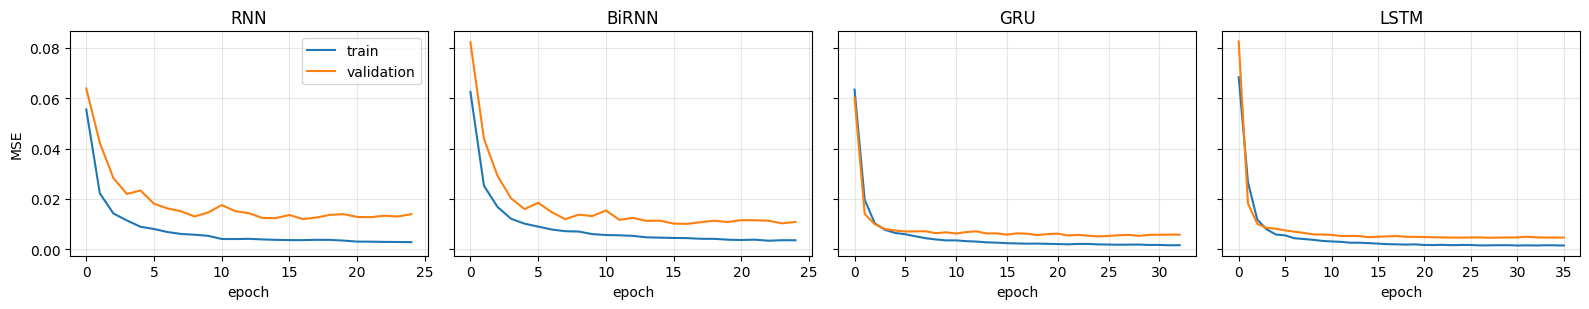

In [ ]:
# ---------------- final training with the best configuration of each architecture ----------------
final = {}
for arch in ARCHS:
    print(f"\n=== {arch} ===")
    model, best, hist = fit(arch, best_cfg[arch], FINAL_EPOCHS, patience=8, verbose=True)
    final[arch] = dict(model=model, hist=hist, best_epoch=best["epoch"])
    torch.save({"state_dict": model.state_dict(), "config": best_cfg[arch], "arch": arch, "itos": itos,
                "thresholds": THRESHOLDS, "max_len": MAX_LEN, "token_mode": TOKEN_MODE}, f"{MODEL_DIR}/{arch}.pt")
    print(f"  best epoch: {best['epoch']} | val RMSE {math.sqrt(best['val']) * 10:.3f}")

fig, axes = plt.subplots(1, 4, figsize=(16, 3.2), sharey=True)
for ax, (arch, d) in zip(axes, final.items()):
    ax.plot(d["hist"]["train"], label="train"); ax.plot(d["hist"]["val"], label="validation")
    ax.set_title(arch); ax.set_xlabel("epoch"); ax.grid(alpha=.3)
axes[0].set_ylabel("MSE"); axes[0].legend(); plt.tight_layout(); plt.show()

## 6 · Evaluation on the test set

**Regression metrics** (score points, 0–10): MAE, MSE, RMSE, R², Pearson and Spearman correlation.
**Classification metrics** (after discretising predicted and true scores into *low / medium / high*): accuracy, macro precision / recall / F1, confusion matrix.

,params,MAE,MSE,RMSE,R2,Pearson,Spearman,Accuracy,Precision,Recall,F1_macro
model,,,,,,,,,,,
RNN,852865,0.622,0.843,0.918,0.722,0.867,0.780,0.741,0.646,0.652,0.649
BiRNN,844673,0.713,1.112,1.055,0.633,0.847,0.764,0.751,0.679,0.621,0.639
GRU,918913,0.577,0.707,0.841,0.766,0.891,0.817,0.793,0.719,0.735,0.726
LSTM,951937,0.570,0.635,0.797,0.790,0.904,0.829,0.793,0.707,0.724,0.713



Best model by macro-F1: GRU

              precision    recall  f1-score   support

         low       0.91      0.87      0.89       119
      medium       0.50      0.53      0.51        38
        high       0.74      0.81      0.77        36

    accuracy                           0.79       193
   macro avg       0.72      0.74      0.73       193
weighted avg       0.80      0.79      0.80       193



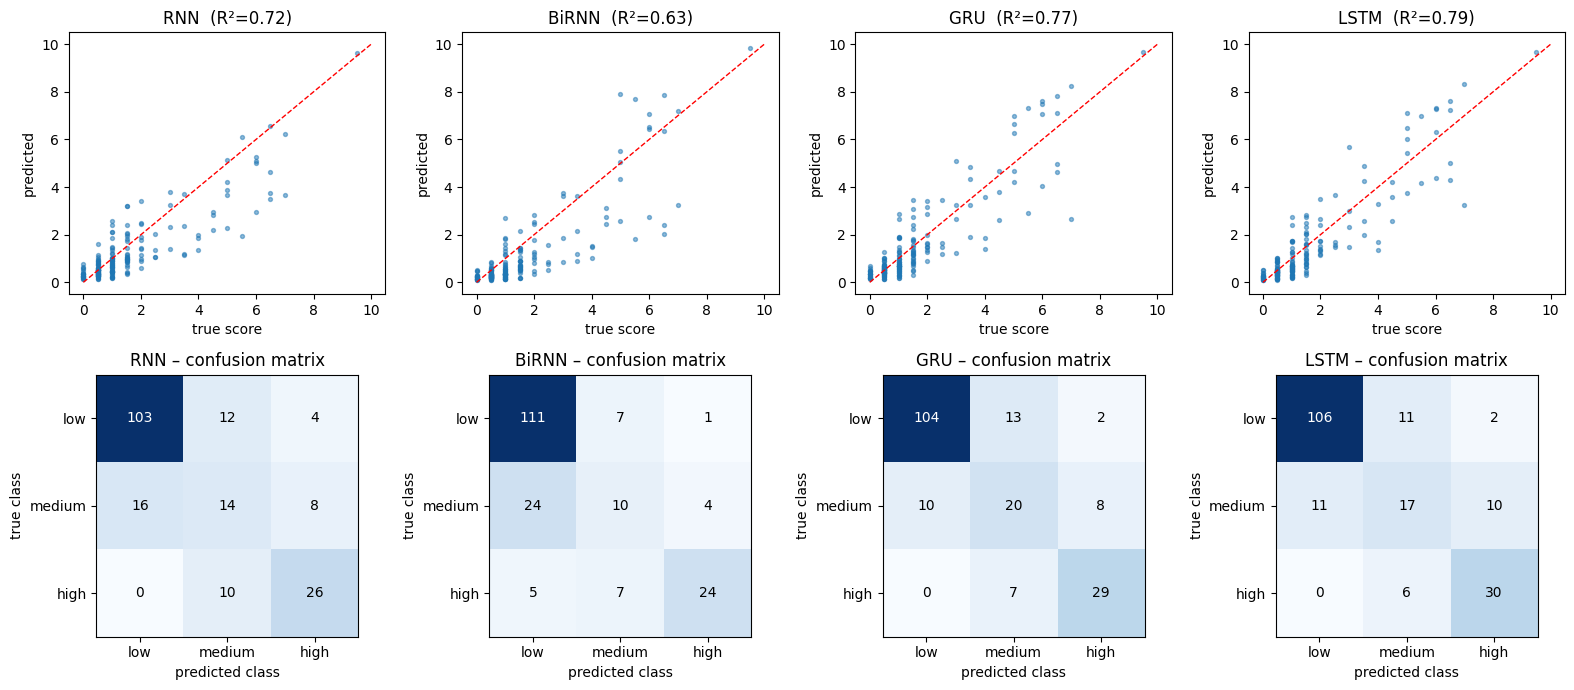

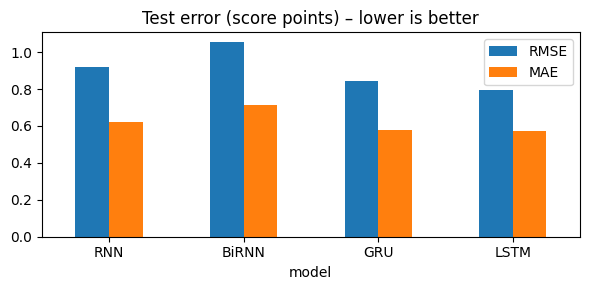

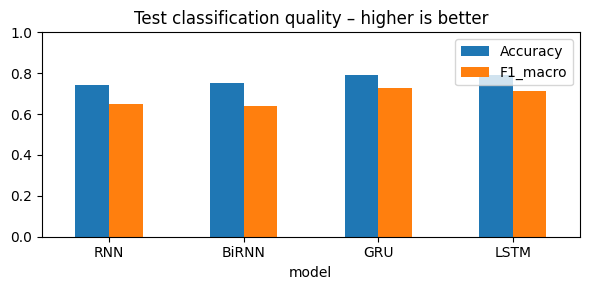

In [ ]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix, classification_report)
from scipy.stats import pearsonr, spearmanr

@torch.no_grad()
def predict(model, split):
    model.eval(); P, T = [], []
    for x, l, y in make_loader(split, 128, False):
        P.append(model(x.to(DEVICE), l).cpu()); T.append(y)
    return torch.cat(P).numpy() * 10, torch.cat(T).numpy() * 10

rows, preds = [], {}
y_true_score = None
for arch, d in final.items():
    p, t = predict(d["model"], test_set); preds[arch] = p; y_true_score = t
    yt, yp = discretize(t), discretize(p)
    prec, rec, f1, _ = precision_recall_fscore_support(yt, yp, average="macro", zero_division=0)
    mse = mean_squared_error(t, p)
    rows.append(dict(model=arch, params=sum(q.numel() for q in d["model"].parameters()),
                     MAE=mean_absolute_error(t, p), MSE=mse, RMSE=math.sqrt(mse), R2=r2_score(t, p),
                     Pearson=pearsonr(t, p)[0], Spearman=spearmanr(t, p)[0],
                     Accuracy=accuracy_score(yt, yp), Precision=prec, Recall=rec, F1_macro=f1))
results_cls = pd.DataFrame(rows).set_index("model")
results_cls.to_csv(f"{DATA_DIR}/results_classification_regression.csv")
display(results_cls.round(3))

best_name = results_cls["F1_macro"].idxmax()
print(f"\nBest model by macro-F1: {best_name}\n")
print(classification_report(discretize(y_true_score), discretize(preds[best_name]), target_names=CLASS_NAMES, zero_division=0))

# ---------------- plots: predicted vs true, confusion matrices ----------------
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, arch in enumerate(ARCHS):
    ax = axes[0, j]; ax.scatter(y_true_score, preds[arch], s=8, alpha=.5); ax.plot([0, 10], [0, 10], "r--", lw=1)
    ax.set_title(f"{arch}  (R²={results_cls.loc[arch, 'R2']:.2f})"); ax.set_xlabel("true score"); ax.set_ylabel("predicted")
    cm = confusion_matrix(discretize(y_true_score), discretize(preds[arch]), labels=[0, 1, 2])
    ax = axes[1, j]; ax.imshow(cm, cmap="Blues")
    for a in range(3):
        for b in range(3): ax.text(b, a, cm[a, b], ha="center", va="center", color="white" if cm[a, b] > cm.max() / 2 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("predicted class"); ax.set_ylabel("true class"); ax.set_title(f"{arch} – confusion matrix")
plt.tight_layout(); plt.show()

results_cls[["RMSE", "MAE"]].plot.bar(figsize=(6, 3), rot=0, title="Test error (score points) – lower is better"); plt.tight_layout(); plt.show()
results_cls[["Accuracy", "F1_macro"]].plot.bar(figsize=(6, 3), rot=0, ylim=(0, 1), title="Test classification quality – higher is better"); plt.tight_layout(); plt.show()

## 7 · The four architectures as *language models*: perplexity and BLEU

BLEU compares **generated text** with a **reference text**, so it cannot be computed on the relevance regressor above. To evaluate the four architectures with BLEU we train, for each of them, a small **word-level language model** on the same split (same train / val / test chunks):

* windows of `LM_LEN = 48` normalised tokens (stop-words are **kept** so that the generated text stays readable);
* **RNN, GRU, LSTM**: next-word prediction, left to right;
* **BiRNN**: a bidirectional RNN whose forward half predicts the next word and whose backward half predicts the previous word (as in ELMo). It is trained with both losses, but **generation only uses the forward half** — a language model must not look at future words.

**Metrics.** *Perplexity* of the forward direction on the test windows (lower is better, identical definition for the four models), and **BLEU-1…4** between the continuation generated from the first 8 tokens of each test window and the real next 20 tokens (greedy decoding, same decoding settings for every model, `<unk>`/`<pad>` never generated).

⚠️ On a corpus this small, BLEU-3/4 will be close to 0 for every model — what matters is the **relative** ranking and BLEU-1/2.

LM windows train/val/test = 4778/306/300 | vocabulary = 12002
RNN    done | test perplexity 597.3 | BLEU-1 0.103 | BLEU-4 0.0006
BiRNN  done | test perplexity 600.1 | BLEU-1 0.111 | BLEU-4 0.0006
GRU    done | test perplexity 593.1 | BLEU-1 0.105 | BLEU-4 0.0006
LSTM   done | test perplexity 552.4 | BLEU-1 0.101 | BLEU-4 0.0005


,val_perplexity,test_perplexity,BLEU-1,BLEU-2,BLEU-3,BLEU-4
model,,,,,,
RNN,532.1679,597.3075,0.1032,0.0204,0.0020,0.0006
BiRNN,539.2115,600.0695,0.1110,0.0221,0.0021,0.0006
GRU,524.4300,593.0597,0.1050,0.0201,0.0020,0.0006
LSTM,494.8300,552.3624,0.1005,0.0157,0.0017,0.0005



Generated continuations (prompt → generation):
[RNN] يعد التعلم العميق او الاعمق في التعليم الامريكي  →  سكوت بيسنت في مجال الذكاء الاصطناعي القوي علي سبيل المثال تتواجد عن طريق الاستنتاج من قبل ان تكون مقيده هو

[RNN] علي اكتساب مهارات مثل التفكير التحليلي وحل المشكلات  →  والادراك علي سبيل المثال تتواجد في ذلك الوقت من خلال الفتره الانتقاليه الثانيه الي ان بعض الشركات الناشئه التي كانت

[BiRNN] يعد التعلم العميق او الاعمق في التعليم الامريكي  →  ان تكون في عام م قدم من خلال الايام الماضيه الي جانب الذكاء الاصطناعي القوي علي سبيل المثال تتواجد عن

[BiRNN] علي اكتساب مهارات مثل التفكير التحليلي وحل المشكلات  →  في عام م قدم من خلال الايام الماضيه الي ان بعض الشركات الناشئه علي ذلك التي كانت هذه الانظمه الخبيره

[GRU] يعد التعلم العميق او الاعمق في التعليم الامريكي  →  في عام م قدم من خلال السنوات الاخيره علي الرغم من ان هذا النوع من الشركات الناشئه الي جانب الذكاء

[GRU] علي اكتساب مهارات مثل التفكير التحليلي وحل المشكلات  →  في عام ميلاديه من خلال السنوات الماضيه الي ان بعض الشركات ا

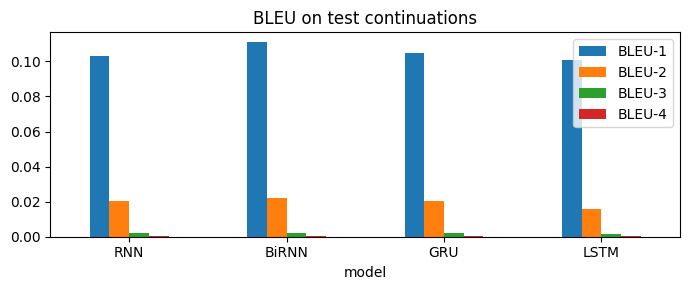

In [ ]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

LM_LEN, PROMPT_LEN, GEN_LEN = 48, 8, 20
LM_EPOCHS = 2 if FAST_DEBUG else 15

def make_windows(toklists, length, stride):
    return [toks[i:i + length] for toks in toklists for i in range(0, len(toks) - length + 1, stride)]

tr_w = make_windows(df.loc[train_idx, "tok_lm"], LM_LEN, LM_LEN // 2)        # overlapping windows for training
va_w = make_windows(df.loc[val_idx, "tok_lm"], LM_LEN, LM_LEN)
te_w = make_windows(df.loc[test_idx, "tok_lm"], LM_LEN, LM_LEN)[:300]
itos_lm, stoi_lm = build_vocab(tr_w, min_freq=2, max_size=12000)
enc = lambda ws: torch.tensor([[stoi_lm.get(t, 1) for t in w] for w in ws], dtype=torch.long)
lm_tr, lm_va, lm_te = enc(tr_w), enc(va_w), enc(te_w)
print(f"LM windows train/val/test = {len(tr_w)}/{len(va_w)}/{len(te_w)} | vocabulary = {len(itos_lm)}")

class LM(nn.Module):
    def __init__(self, vocab_size, rnn_type, bidirectional, emb_dim=128, hidden=256, dropout=0.3):
        super().__init__()
        self.hidden, self.bi = hidden, bidirectional
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=0)
        rnn_cls = {"RNN": nn.RNN, "GRU": nn.GRU, "LSTM": nn.LSTM}[rnn_type]
        self.rnn = rnn_cls(emb_dim, hidden, batch_first=True, bidirectional=bidirectional)   # 1 layer: no leakage between directions
        self.drop = nn.Dropout(dropout)
        self.fwd = nn.Linear(hidden, vocab_size)
        self.bwd = nn.Linear(hidden, vocab_size) if bidirectional else None
    def forward(self, x):
        out, _ = self.rnn(self.drop(self.emb(x))); out = self.drop(out)
        f = self.fwd(out[..., :self.hidden])                                  # forward half -> next word
        b = self.bwd(out[..., self.hidden:]) if self.bi else None            # backward half -> previous word
        return f, b
    @torch.no_grad()
    def next_logits(self, x):                                                # uses the forward half only
        out, _ = self.rnn(self.emb(x))
        return self.fwd(out[:, -1, :self.hidden])

def fwd_nll(f, x):  return F.cross_entropy(f[:, :-1].reshape(-1, f.size(-1)), x[:, 1:].reshape(-1))
def bwd_nll(b, x):  return F.cross_entropy(b[:, 1:].reshape(-1, b.size(-1)), x[:, :-1].reshape(-1))

@torch.no_grad()
def lm_perplexity(model, X):
    model.eval(); tot, n = 0.0, 0
    for (x,) in DataLoader(TensorDataset(X), batch_size=256):
        x = x.to(DEVICE); f, _ = model(x)
        tot += fwd_nll(f, x).item() * x[:, 1:].numel(); n += x[:, 1:].numel()
    return math.exp(tot / n)

def train_lm(arch, epochs, lr=2e-3, bs=64, patience=3):
    set_seed()
    model = LM(len(itos_lm), **ARCHS[arch]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loader = DataLoader(TensorDataset(lm_tr), batch_size=bs, shuffle=True)
    best, state, bad = float("inf"), None, 0
    for ep in range(1, epochs + 1):
        model.train()
        for (x,) in loader:
            x = x.to(DEVICE); f, b = model(x)
            loss = fwd_nll(f, x) + (bwd_nll(b, x) if b is not None else 0.0)
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
        ppl = lm_perplexity(model, lm_va)
        if ppl < best - 1e-3: best, bad, state = ppl, 0, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state)
    return model, best

@torch.no_grad()
def generate(model, prompts, n_new, penalty=2.0):                      # greedy decoding + repetition penalty
    model.eval(); x = prompts.to(DEVICE); P = x.size(1)
    for _ in range(n_new):
        logits = model.next_logits(x)
        logits[:, :2] = -1e9                                           # never generate <pad> / <unk>
        if x.size(1) > P:                                              # penalise words already generated
            pen = torch.zeros_like(logits); pen.scatter_(1, x[:, P:], penalty); logits = logits - pen
        x = torch.cat([x, logits.argmax(-1, keepdim=True)], dim=1)
    return x[:, P:].cpu()

smooth = SmoothingFunction().method1
refs = [[w[PROMPT_LEN:PROMPT_LEN + GEN_LEN]] for w in te_w]            # real continuations (original words)

lm_rows, samples = [], {}
for arch in ARCHS:
    model, val_ppl = train_lm(arch, LM_EPOCHS)
    gen = generate(model, lm_te[:, :PROMPT_LEN], GEN_LEN)
    hyps = [[itos_lm[i] for i in row.tolist()] for row in gen]
    bleu = {f"BLEU-{n}": corpus_bleu(refs, hyps, weights=tuple([1 / n] * n), smoothing_function=smooth) for n in (1, 2, 3, 4)}
    lm_rows.append(dict(model=arch, val_perplexity=val_ppl, test_perplexity=lm_perplexity(model, lm_te), **bleu))
    samples[arch] = [(" ".join(te_w[i][:PROMPT_LEN]), " ".join(hyps[i])) for i in range(2)]
    print(f"{arch:6s} done | test perplexity {lm_rows[-1]['test_perplexity']:.1f} | BLEU-1 {bleu['BLEU-1']:.3f} | BLEU-4 {bleu['BLEU-4']:.4f}")

results_lm = pd.DataFrame(lm_rows).set_index("model")
results_lm.to_csv(f"{DATA_DIR}/results_language_models.csv")
display(results_lm.round(4))

print("\nGenerated continuations (prompt → generation):")
for arch, ex in samples.items():
    for prompt, gen_txt in ex: print(f"[{arch}] {prompt}  →  {gen_txt}\n")
results_lm[["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4"]].plot.bar(figsize=(7, 3), rot=0, title="BLEU on test continuations"); plt.tight_layout(); plt.show()

## 8 · Summary table, saved artefacts, and  synthesis

In [ ]:
summary = results_cls[["RMSE", "MAE", "R2", "Accuracy", "F1_macro"]].join(results_lm[["test_perplexity", "BLEU-1", "BLEU-2", "BLEU-4"]])
summary.to_csv(f"{DATA_DIR}/summary_part1.csv")
display(summary.round(3))
print("Saved: data/dataset.csv, data/dataset_full.csv, data/raw_texts.csv, data/tuning_results.csv, data/summary_part1.csv, models/*.pt")


try:
    import shutil; from google.colab import files
    shutil.make_archive("part1_outputs", "zip", ".", DATA_DIR); files.download("part1_outputs.zip")
except Exception:
    pass

,RMSE,MAE,R2,Accuracy,F1_macro,test_perplexity,BLEU-1,BLEU-2,BLEU-4
model,,,,,,,,,
RNN,0.918,0.622,0.722,0.741,0.649,597.308,0.103,0.020,0.001
BiRNN,1.055,0.713,0.633,0.751,0.639,600.070,0.111,0.022,0.001
GRU,0.841,0.577,0.766,0.793,0.726,593.060,0.105,0.020,0.001
LSTM,0.797,0.570,0.790,0.793,0.713,552.362,0.100,0.016,0.001


Saved: data/dataset.csv, data/dataset_full.csv, data/raw_texts.csv, data/tuning_results.csv, data/summary_part1.csv, models/*.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

###  Synthesis & Empirical Analysis

#### 1. Insights from the Arabic NLP Pipeline
Our preprocessing pipeline highlights the rich and complex morphology of the Arabic language. By stripping punctuation, diacritics (*tashkeel*), and lengthening symbols (*tatweel*), we standardized basic spelling variations. However, the most profound impact on our model vocabulary came from **lemmatisation** and **stop-word removal**:
* **Vocabulary Reduction:** In the raw dataset, words appear in countless inflected forms due to Arabic prefixes (like conjunctions *و*, prepositions *بـ/لـ*, and the definite article *الـ*) and suffixes. Implementing the `qalsadi` lemmatizer collapsed these forms to their dictionary roots (e.g., *الأطفال → طفل*), reducing the overall unique word count and drastically lowering data sparsity.
* **Semantic Filtering:** Removing custom and NLTK Arabic stop-words successfully eliminated high-frequency function words (such as *في*, *من*, *على*, *كان*), which carry no topic-specific signals. This forced our models to focus strictly on semantic content words (*ذكاء*, *علم*, *نظام*).

#### 2. Architecture Comparison: Why the Gated Models Won
Based on our final test evaluations, the architectures performed as follows:
* **GRU** was our best performer by Macro-F1 (**0.726**), achieving an Accuracy of **79.3%** and an RMSE of **0.841**.
* **LSTM** closely followed with an Accuracy of **79.3%**, an F1 of **0.713**, and our best overall R² of **0.79** (lowest RMSE of **0.797**).
* **RNN** achieved an F1 of **0.649** and an R² of **0.72**.
* **BiRNN** obtained an F1 of **0.639** and an R² of **0.63**.

**Theoretical Analysis:**
* **Vanishing Gradients & Gating Mechanisms:** The standard RNN struggled on our longer sequences because it suffers from vanishing gradients over time. In contrast, **GRU** and **LSTM** utilize gating mechanisms (reset/update gates in GRU; input/forget/output gates in LSTM) that allow error gradients to flow backward through long sequences without exponentially decaying. This enables them to retain context over the entire 112-token sequence.
* **Bidirectional vs. Unidirectional:** While bidirectional layers (`BiRNN`) theoretically capture both left-to-right and right-to-left contexts, with a vanilla RNN structure it often introduces more parameters to train on a relatively small dataset, sometimes leading to overfitting or optimization difficulties on test data compared to its unidirectional counterpart.
* **The Impact of Pooling:** Pooling choice was highly influential. Our hyper-parameter tuning (visible in `tuning_results.csv`) demonstrated that `pooling = "last"` significantly harmed the vanilla RNN because the network tended to "forget" early sequence tokens by the final step. Switching to `pooling = "mean"` (masked mean over all time steps) salvaged the RNN's performance by directly carrying semantic signals from early time steps to the classification head.

#### 3. Key Hyper-parameters
During our tuning trials, the hyper-parameters that mattered most were:
1. **Learning Rate (LR):** A rate of `1e-3` worked best as a baseline, while higher rates (`3e-3`) often caused unstable loss curves or premature convergence on local minima.
2. **Pooling Strategy:** `mean` pooling consistently outperformed `last` pooling across almost all architectures, especially for non-gated networks.
3. **Dropout:** Setting dropout to `0.3` provided crucial regularization, preventing the model from over-memorizing our vocabulary on the small dataset.

#### 4. Limitations of the Evaluation
* **Weak Supervision Labels:** The ground-truth relevance scores (0 to 10) were generated automatically using a lexicon and TF-IDF similarity. Consequently, our models are trained to mimic an automated heuristic rather than genuine human understanding.
* **Page-Grouped Split:** To prevent data leakage, we grouped our splits by URL using `StratifiedGroupKFold`. This makes our validation metrics realistic but also much harder, as the test set consists entirely of unseen articles with distinct vocabulary and writing styles.
* **BLEU Limitations:** In our language-modeling tasks, BLEU scores are extremely low across all architectures (ranging from `0.10` to `0.11` for BLEU-1, and nearly `0` for BLEU-4). On a tiny corpus, generating exact 4-gram matches is rare. Thus, these metrics must be interpreted purely as relative indicators of predictive alignment.

#### 5. Future Directions
To elevate this project further, we should:
1. **Incorporate Human Labels:** Collect a manually annotated subset of texts to establish a gold-standard evaluation set.
2. **Leverage Pre-trained Embeddings:** Replace our randomly initialized embeddings with pre-trained Arabic representations like **AraVec** or **fastText Arabic** to capture rich semantic relationships from the start.
3. **Transition to Transformers:** Fine-tune a specialized masked language model such as **AraBERT**, which handles bidirectional context much more effectively than LSTMs through self-attention mechanisms.